# Calibration

In [17]:
import glob
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---- À ADAPTER ----
IMAGES_DIR = "images"
COLS, ROWS = 8, 5          # coins intérieurs (horizontal, vertical)
SQUARE_MM = 20             # taille réelle d'un carré en mm
MAX_DIM = 1600             # réduction pour accélérer la détection (0 = aucune)
# -------------------

OUT_CORNERS = "output/corners"
OUT_RESULTS = "results"
os.makedirs(OUT_CORNERS, exist_ok=True)
os.makedirs(OUT_RESULTS, exist_ok=True)

PATTERN = (COLS, ROWS)
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


1. Définir les points 3D du damie

In [18]:
objp = np.zeros((ROWS * COLS, 3), np.float32)
objp[:, :2] = np.mgrid[0:COLS, 0:ROWS].T.reshape(-1, 2)
objp *= SQUARE_MM

print(objp.shape)
print(objp[:4])

(40, 3)
[[ 0.  0.  0.]
 [20.  0.  0.]
 [40.  0.  0.]
 [60.  0.  0.]]


2. Détection des coins

In [19]:
def list_images(folder):
    files = []
    for e in ("jpg", "jpeg", "png", "bmp"):
        files += glob.glob(os.path.join(folder, f"*.{e}"))
        files += glob.glob(os.path.join(folder, f"*.{e.upper()}"))
    return sorted(set(files))


def find_corners(gray, pattern, max_dim):
    """Détection sur image réduite, affinement sub-pixel en pleine résolution."""
    h, w = gray.shape
    scale, small = 1.0, gray
    if max_dim and max(h, w) > max_dim:
        scale = max_dim / max(h, w)
        small = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

    flags = cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
    found, corners = cv2.findChessboardCorners(small, pattern, flags)
    if not found:
        return False, None

    corners = (corners / scale).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
    corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)
    return True, corners


files = list_images(IMAGES_DIR)
print(f"{len(files)} images trouvées dans '{IMAGES_DIR}'")

objpoints, imgpoints, used, rejected, previews = [], [], [], [], []
image_size = None  # (largeur, hauteur)

for path in files:
    name = os.path.basename(path)
    img = cv2.imread(path)  # applique l'orientation EXIF
    if img is None:
        print(f"[ERREUR] lecture impossible : {name}")
        rejected.append(name)
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    size = (gray.shape[1], gray.shape[0])
    if image_size is None:
        image_size = size
    elif size != image_size:
        print(f"[IGNORÉE] {name} : taille {size} différente de {image_size}")
        rejected.append(name)
        continue

    found, corners = find_corners(gray, PATTERN, MAX_DIM)
    if not found:
        print(f"[NON DÉTECTÉ] {name}")
        rejected.append(name)
        continue

    objpoints.append(objp)
    imgpoints.append(corners)
    used.append(name)

    vis = img.copy()
    cv2.drawChessboardCorners(vis, PATTERN, corners, True)
    cv2.imwrite(os.path.join(OUT_CORNERS, f"corners_{name}"), vis)
    previews.append((name, vis))
    print(f"[OK] {name}")

print(f"\nImages utilisées : {len(used)} / {len(files)}")
if 0 < len(used) < 10:
    print("ATTENTION : moins de 10 images valides, prenez plus de photos variées.")

35 images trouvées dans 'images'
[NON DÉTECTÉ] IMG20261104234334.jpg
[NON DÉTECTÉ] IMG20261104234342.jpg
[NON DÉTECTÉ] IMG20261104234349.jpg
[NON DÉTECTÉ] IMG20261104234353.jpg
[NON DÉTECTÉ] IMG20261104234407.jpg
[NON DÉTECTÉ] IMG20261104234409.jpg
[NON DÉTECTÉ] IMG20261104234518.jpg
[OK] IMG20261104234521.jpg
[OK] IMG20261104234523.jpg
[NON DÉTECTÉ] IMG20261104234526.jpg
[NON DÉTECTÉ] IMG20261104234532.jpg
[NON DÉTECTÉ] IMG20261104234533.jpg
[OK] IMG20261104234536.jpg
[NON DÉTECTÉ] IMG20261104234538.jpg
[OK] IMG20261104234540.jpg
[NON DÉTECTÉ] IMG20261104234543.jpg
[NON DÉTECTÉ] IMG20261104234546.jpg
[OK] IMG20261104234551.jpg
[NON DÉTECTÉ] IMG20261104234553.jpg
[NON DÉTECTÉ] IMG20261104234604.jpg
[NON DÉTECTÉ] IMG20261104234607.jpg
[NON DÉTECTÉ] IMG20261104234608.jpg
[OK] IMG20261104234620.jpg
[IGNORÉE] IMG20261104234621.jpg : taille (3072, 4080) différente de (4080, 3072)
[NON DÉTECTÉ] IMG20261104234625.jpg
[NON DÉTECTÉ] IMG20261104234626.jpg
[OK] IMG20261104234628.jpg
[NON DÉTECTÉ]

Aperçu des détections

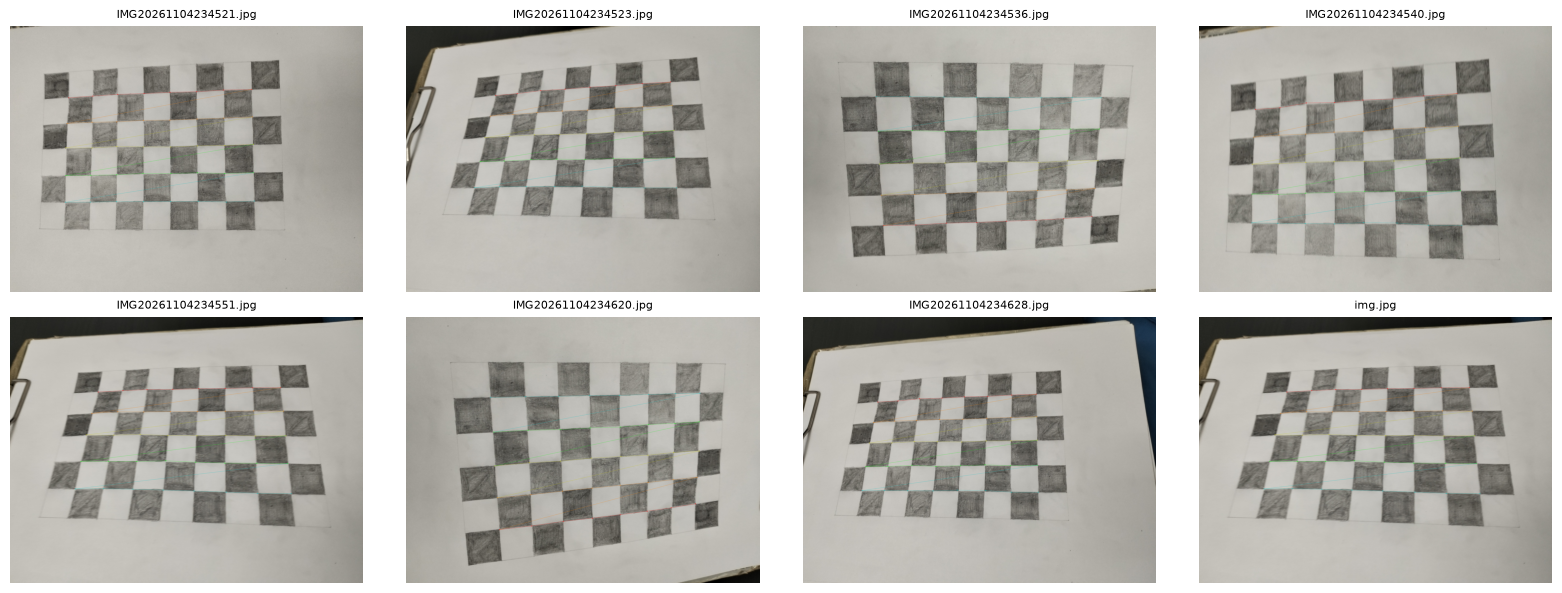

In [20]:
def show_grid(items, ncols=4, max_items=12):
    items = items[:max_items]
    if not items:
        print("Rien à afficher.")
        return
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (name, im) in zip(axes, items):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))  # BGR -> RGB
        ax.set_title(name, fontsize=8)
    plt.tight_layout()
    plt.show()

show_grid(previews)

3. Calibration (`cv2.calibrateCamera`)

In [21]:
rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, image_size, None, None
)

print(f"Taille image : {image_size[0]} x {image_size[1]} px")
print(f"RMS (calibrateCamera) : {rms:.4f} px\n")
print("Matrice intrinsèque K :")
print(np.array2string(K, precision=3, suppress_small=True))
print(f"\nfx = {K[0,0]:.2f} px   fy = {K[1,1]:.2f} px")
print(f"cx = {K[0,2]:.2f} px   cy = {K[1,2]:.2f} px")
print("\nDistorsion (k1, k2, p1, p2, k3) :")
print(dist.ravel())

Taille image : 4080 x 3072 px
RMS (calibrateCamera) : 7.1164 px

Matrice intrinsèque K :
[[3397.964    0.    2019.092]
 [   0.    3427.786 1567.207]
 [   0.       0.       1.   ]]

fx = 3397.96 px   fy = 3427.79 px
cx = 2019.09 px   cy = 1567.21 px

Distorsion (k1, k2, p1, p2, k3) :
[ 2.82857868e-01 -2.18059675e+00  6.93583275e-03  5.25498310e-04
  4.03483732e+00]


4. Erreur de reprojection

Erreur moyenne : 7.0764 px
  IMG20261104234521.jpg          6.3447 px
  IMG20261104234523.jpg          6.3736 px
  IMG20261104234536.jpg          7.8121 px
  IMG20261104234540.jpg          8.6230 px
  IMG20261104234551.jpg          6.8359 px
  IMG20261104234620.jpg          7.3347 px
  IMG20261104234628.jpg          6.4513 px
  img.jpg                        6.8359 px


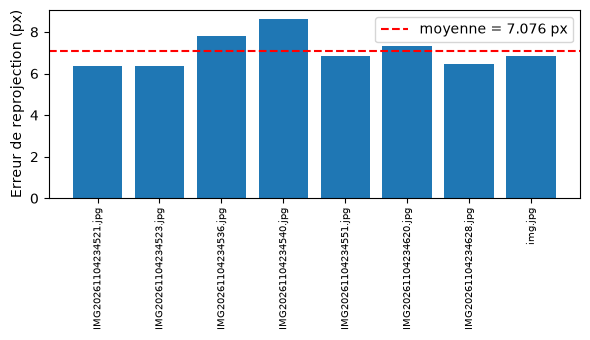

In [22]:
errors = []
for i in range(len(objpoints)):
    proj, _ = cv2.projectPoints(objpoints[i], rvecs[i], tvecs[i], K, dist)
    a = imgpoints[i].reshape(-1, 2)
    b = proj.reshape(-1, 2)
    err = np.sqrt(np.mean(np.sum((a - b) ** 2, axis=1)))  # RMS en pixels
    errors.append(err)
errors = np.array(errors)

print(f"Erreur moyenne : {errors.mean():.4f} px")
for n, e in zip(used, errors):
    print(f"  {n:30s} {e:.4f} px")

plt.figure(figsize=(max(6, 0.4 * len(used)), 3.5))
plt.bar(range(len(errors)), errors)
plt.axhline(errors.mean(), color="r", ls="--", label=f"moyenne = {errors.mean():.3f} px")
plt.xticks(range(len(errors)), used, rotation=90, fontsize=7)
plt.ylabel("Erreur de reprojection (px)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_RESULTS, "reprojection_error.png"), dpi=150)
plt.show()

5. Sauvegarde dans results

In [23]:
np.savez(
    os.path.join(OUT_RESULTS, "calib.npz"),
    K=K,
    dist=dist,
    rvecs=np.array(rvecs),
    tvecs=np.array(tvecs),
    rms=rms,
    errors=errors,
    image_size=np.array(image_size),
    pattern_size=np.array(PATTERN),
    square_size=SQUARE_MM,
    used_images=np.array(used),
    objpoints=np.array(objpoints),
    imgpoints=np.array(imgpoints),
)
print("Sauvegardé :", os.path.join(OUT_RESULTS, "calib.npz"))
if rejected:
    print("Images rejetées :", rejected)

# data = np.load("results/calib.npz"); K, dist = data["K"], data["dist"]

Sauvegardé : results/calib.npz
Images rejetées : ['IMG20261104234334.jpg', 'IMG20261104234342.jpg', 'IMG20261104234349.jpg', 'IMG20261104234353.jpg', 'IMG20261104234407.jpg', 'IMG20261104234409.jpg', 'IMG20261104234518.jpg', 'IMG20261104234526.jpg', 'IMG20261104234532.jpg', 'IMG20261104234533.jpg', 'IMG20261104234538.jpg', 'IMG20261104234543.jpg', 'IMG20261104234546.jpg', 'IMG20261104234553.jpg', 'IMG20261104234604.jpg', 'IMG20261104234607.jpg', 'IMG20261104234608.jpg', 'IMG20261104234621.jpg', 'IMG20261104234625.jpg', 'IMG20261104234626.jpg', 'IMG20261104234631.jpg', 'IMG20261104234634.jpg', 'IMG20261104234636.jpg', 'IMG20261104234641.jpg', 'IMG20261104234642.jpg', 'IMG20261104234644_01.jpg', 'image.jpg']


6. correction de la distorsion

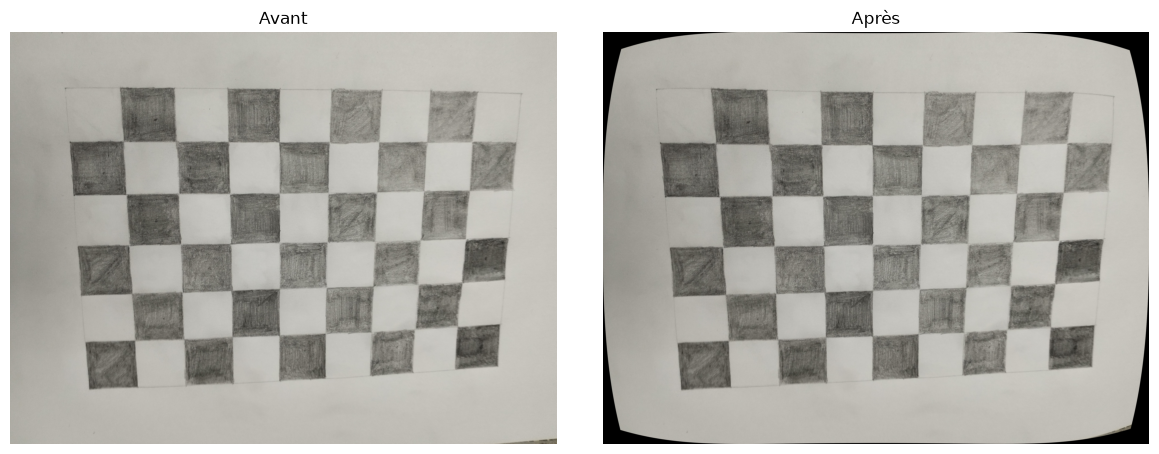

In [25]:
name = used[2]
img = cv2.imread(os.path.join(IMAGES_DIR, name))
h, w = img.shape[:2]
newK, roi = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 1, (w, h))
und = cv2.undistort(img, K, dist, None, newK)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title("Avant"); ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(und, cv2.COLOR_BGR2RGB)); ax[1].set_title("Après"); ax[1].axis("off")
plt.tight_layout()
plt.show()